# Day 20: NFL play-by-play EDA: offensive patterns

**Phase 2: EDA & Feature Engineering**

## Objective
NFL play-by-play EDA: offensive patterns

## Task
Analyze play distribution by down & distance, EPA by play type, pass/run ratio trends by game situation. Create EPA distribution visualizations by team and QB.

**Deliverable:** Notebook day020_nfl_offensive_eda.ipynb with offensive pattern analysis.

---

### Instructions:
*Treat this as your course workbook. Write your code, notes, or execution steps below.*

Remember: 
- Document your decisions.
- Use clear variable names.
- If today's task involves creating a script in `src/`, a dashboard in `apps/`, or documentation in `docs/`, you can use this notebook to test your logic or simply write your reflections and proofs of execution (e.g. running terminal commands with `!`).



## Step 1: Data Loading & Situational Cleaning

In NFL analytics, analyzing offensive patterns requires isolating clean scrimmage plays:
- We filter `play_type` to `pass` and `run` (excluding special teams, punts, field goals, kneels, and spikes).
- We require `down.notna()` (which excludes 2-point conversions and untimed plays) and cast `down` to integer.
- We verify `epa.notna()`.
- We create a baseline `success` binary indicator (`epa > 0`), which is the standard definition of a successful play in modern NFL metrics.

In [7]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Styling setup
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

# Data paths relative to notebooks directory
data_dir = Path("../../data/processed/nfl")
plays_path = data_dir / "fact_plays.parquet"
players_path = data_dir / "dim_players.parquet"
games_path = data_dir / "dim_games.parquet"

# Load datasets
df_plays = pd.read_parquet(plays_path)
df_players = pd.read_parquet(players_path)
df_games = pd.read_parquet(games_path)

print(f"Raw plays loaded: {len(df_plays):,}")
print(f"Total games: {len(df_games):,}")
print(f"Total players in roster: {len(df_players):,}")

# Filter for clean offensive scrimmage plays
offensive_plays = df_plays[
    (df_plays["play_type"].isin(["pass", "run"]))
    & (df_plays["down"].notna())
    & (df_plays["epa"].notna())
].copy()

# Standardize types and add success indicator (EPA > 0)
offensive_plays["down"] = offensive_plays["down"].astype(int)
offensive_plays["success"] = (offensive_plays["epa"] > 0).astype(int)

print(f"\nFiltered clean offensive plays: {len(offensive_plays):,} ({len(offensive_plays) / len(df_plays):.1%} of raw plays)")
display(offensive_plays[["play_id", "posteam", "defteam", "down", "ydstogo", "yardline_100", "play_type", "yards_gained", "epa", "success"]].head(5))


Raw plays loaded: 49,665
Total games: 285
Total players in roster: 3,089

Filtered clean offensive plays: 35,474 (71.4% of raw plays)


,play_id,posteam,defteam,down,ydstogo,yardline_100,play_type,yards_gained,epa,success
2,2023_01_ARI_WAS_55.0,WAS,ARI,1,10.0,75.0,run,3.0,-0.336103,0
3,2023_01_ARI_WAS_77.0,WAS,ARI,2,7.0,72.0,pass,6.0,0.703308,1
4,2023_01_ARI_WAS_102.0,WAS,ARI,3,1.0,66.0,run,2.0,0.469799,1
5,2023_01_ARI_WAS_124.0,WAS,ARI,1,10.0,64.0,pass,0.0,-0.521544,0
6,2023_01_ARI_WAS_147.0,WAS,ARI,2,10.0,64.0,pass,12.0,1.173154,1


## Step 2: Play Distribution by Down & Distance and Play Type

We segment plays by situational context:
1. **Down:** 1st, 2nd, 3rd, and 4th down.
2. **Distance Buckets:**
   - `Short (1-3 yds)`: Power run, QB sneak, short RPO territory.
   - `Medium (4-7 yds)`: Balanced playbook open for both run and pass.
   - `Long (8+ yds)`: Clear passing situations where defenses unleash subpackages and pass rushers.

We evaluate three core efficiency and consistency metrics:
- **Play Volume & Play-Calling Frequency** (Pass vs. Run count).
- **Mean Expected Points Added (EPA)**.
- **Success Rate** (percentage of plays with positive EPA).

=== Down-Level Performance Summary ===


,down,play_type,plays,mean_epa,median_epa,success_rate,mean_yards
0,1,pass,7556,0.031797,-0.084909,0.469561,6.760984
1,1,run,7879,-0.095243,-0.203527,0.363371,4.399162
2,2,pass,6872,0.019787,-0.165868,0.451542,5.853318
3,2,run,4877,-0.037460,-0.145346,0.422186,4.366004
4,3,pass,5691,-0.098830,-0.731526,0.379371,5.611140
5,3,run,1766,0.074362,0.316126,0.543601,4.463194
6,4,pass,525,-0.352018,-1.917927,0.411429,4.571429
7,4,run,308,0.598039,1.876750,0.698052,3.129870


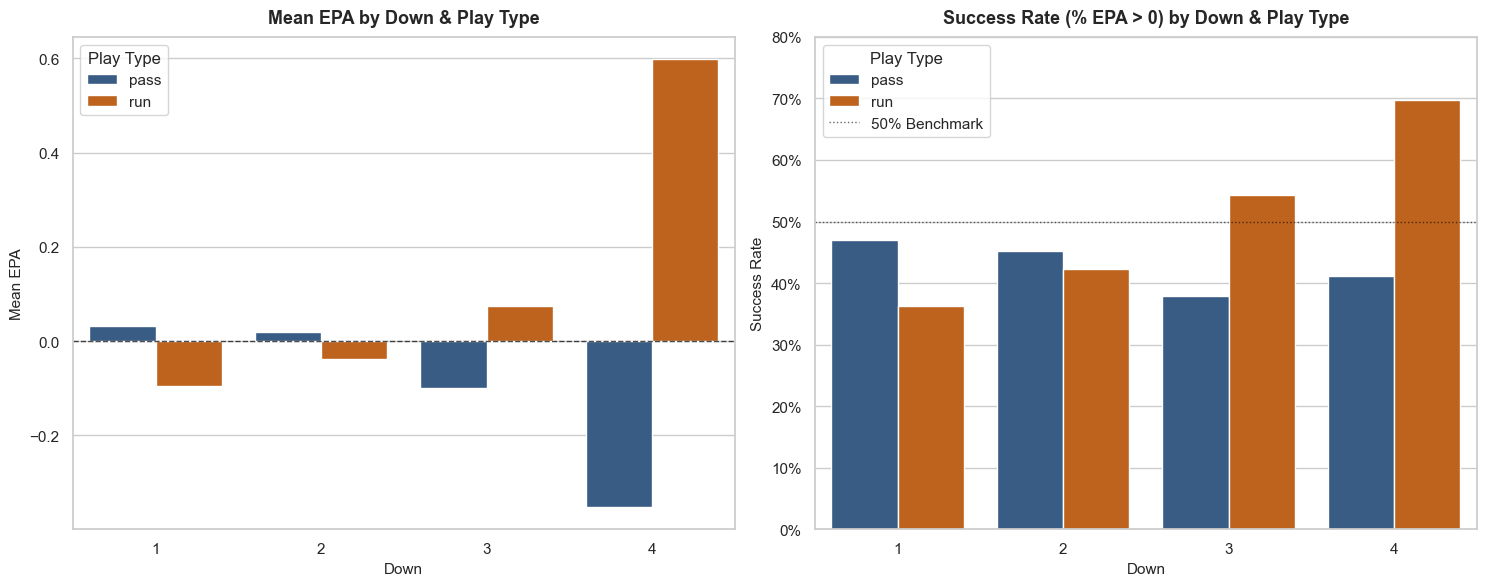

In [8]:
# Define distance buckets
distance_bins = [0, 3, 7, 100]
distance_labels = ["Short (1-3 yds)", "Medium (4-7 yds)", "Long (8+ yds)"]
offensive_plays["distance_bucket"] = pd.cut(
    offensive_plays["ydstogo"],
    bins=distance_bins,
    labels=distance_labels,
    right=True
)

# 1. Down-level aggregation
down_summary = offensive_plays.groupby(["down", "play_type"]).agg(
    plays=("epa", "count"),
    mean_epa=("epa", "mean"),
    median_epa=("epa", "median"),
    success_rate=("success", "mean"),
    mean_yards=("yards_gained", "mean")
).reset_index()

print("=== Down-Level Performance Summary ===")
display(down_summary)

# 2. Detailed Down & Distance breakdown
distance_summary = offensive_plays.groupby(
    ["down", "distance_bucket", "play_type"],
    observed=False
).agg(
    plays=("epa", "count"),
    mean_epa=("epa", "mean"),
    success_rate=("success", "mean"),
    mean_yards=("yards_gained", "mean")
).reset_index()

# Visualization: Mean EPA and Success Rate by Down & Play Type
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Mean EPA by Down
palette = {"pass": "#2b5c8f", "run": "#d95f02"}
sns.barplot(
    data=down_summary,
    x="down",
    y="mean_epa",
    hue="play_type",
    palette=palette,
    ax=axes[0]
)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)
axes[0].set_title("Mean EPA by Down & Play Type", fontsize=13, fontweight="bold", pad=10)
axes[0].set_xlabel("Down", fontsize=11)
axes[0].set_ylabel("Mean EPA", fontsize=11)
axes[0].legend(title="Play Type", frameon=True)

# Subplot 2: Success Rate by Down
sns.barplot(
    data=down_summary,
    x="down",
    y="success_rate",
    hue="play_type",
    palette=palette,
    ax=axes[1]
)
axes[1].axhline(0.5, color="black", linestyle=":", linewidth=1, alpha=0.6, label="50% Benchmark")
axes[1].set_title("Success Rate (% EPA > 0) by Down & Play Type", fontsize=13, fontweight="bold", pad=10)
axes[1].set_xlabel("Down", fontsize=11)
axes[1].set_ylabel("Success Rate", fontsize=11)
axes[1].set_ylim(0, 0.8)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
axes[1].legend(title="Play Type", frameon=True)

plt.tight_layout()
plt.show()


### Tactical & Statistical Findings from Down & Distance Analysis:

1. **Early Down Pass Efficiency vs. Conventional Coaching Bias:**
   - On **1st down**, passing generates **+0.032 Mean EPA** (with a **47.0% success rate** and 6.76 yards/play), whereas running produces **-0.095 Mean EPA** (only **36.3% success rate** and 4.40 yards/play).
   - On **1st & 10 specifically**, passing holds a massive **+0.146 EPA advantage** over rushing (+0.045 vs. -0.101).
   - Despite this clear statistical edge, NFL play-callers still executed more runs (7,879) than passes (7,556) on 1st down, illustrating how traditional 'establish the run' doctrine lags behind empirical efficiency.

2. **Selection Bias in 3rd & 4th Down Efficiency:**
   - On **3rd down**, running appears to produce positive EPA (+0.074, 54.4% success) while passing is negative (-0.099, 37.9% success). This is classic **selection bias**: offenses only run on 3rd down when facing short yardage (3rd & 1-2), whereas passing is forced on 3rd & long where defenses drop deep coverage and unleash pass rushers.
   - On **4th down**, short-yardage power runs and QB sneaks convert at a remarkable **69.8% success rate** (+0.598 Mean EPA), underscoring the analytical mandate to go for it on 4th & short.

## Step 3: Situational Pass/Run Ratio & Aggressiveness Across Field Zones

Field position fundamentally reshapes defensive spacing and offensive risk profiles. We segment the field into 4 tactical zones using `yardline_100` (distance to opponent's endzone):
1. **Backed Up (`81-99` yds):** Deep in own territory, near own goal line. High turnover/safety penalty.
2. **Own Half (`51-80` yds):** Midfield build-up. Defenses protect against explosive plays.
3. **Opponent Half (`21-50` yds):** Approach to scoring range. Play action and aggressive shots are common.
4. **Red Zone (`1-20` yds):** Compressed field. The end line removes vertical depth, allowing defenders to swarm short areas.

=== Field Zone Tactical Breakdown ===


,field_zone,total_plays,pass_rate,run_rate,overall_mean_epa,pass_mean_epa,run_mean_epa,pass_success,run_success
0,1. Backed Up (81-99),2879,0.574852,0.425148,-0.069156,-0.016973,-0.139715,0.413293,0.321078
1,2. Own Half (51-80),16786,0.611343,0.388657,-0.027277,-0.008388,-0.056989,0.447671,0.404506
2,3. Opponent Half (21-50),10622,0.578046,0.421954,-0.023917,-0.017223,-0.033086,0.447557,0.425033
3,4. Red Zone (1-20),5187,0.498747,0.501253,-0.014958,-0.058405,0.028272,0.386548,0.446154


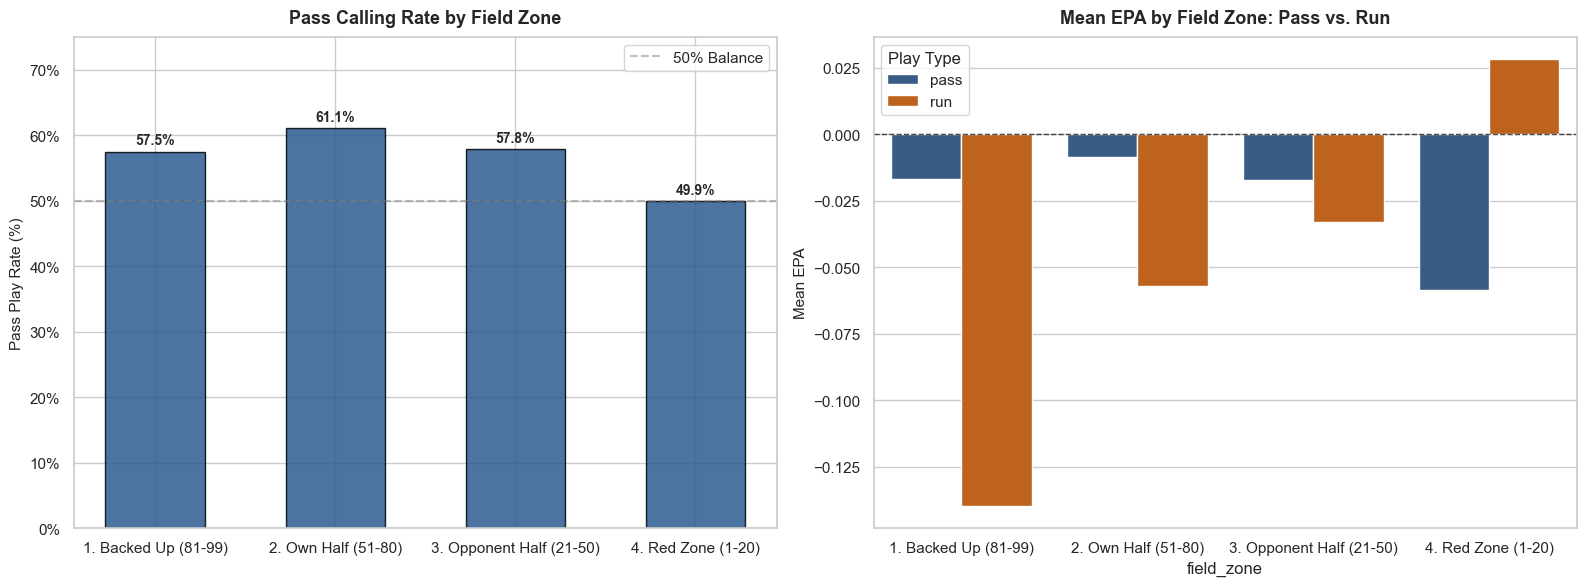

In [9]:
# Define field zones based on distance to opponent end zone (yardline_100)
def categorize_field_zone(yardline):
    if yardline <= 20:
        return "4. Red Zone (1-20)"
    elif yardline <= 50:
        return "3. Opponent Half (21-50)"
    elif yardline <= 80:
        return "2. Own Half (51-80)"
    else:
        return "1. Backed Up (81-99)"

offensive_plays["field_zone"] = offensive_plays["yardline_100"].apply(categorize_field_zone)

# Aggregate metrics by field zone and play type
zone_breakdown = offensive_plays.groupby("field_zone").agg(
    total_plays=("play_id", "count"),
    pass_plays=("play_type", lambda x: (x == "pass").sum()),
    run_plays=("play_type", lambda x: (x == "run").sum()),
    overall_mean_epa=("epa", "mean"),
    pass_mean_epa=("epa", lambda s: s[offensive_plays.loc[s.index, "play_type"] == "pass"].mean()),
    run_mean_epa=("epa", lambda s: s[offensive_plays.loc[s.index, "play_type"] == "run"].mean()),
    pass_success=("success", lambda s: s[offensive_plays.loc[s.index, "play_type"] == "pass"].mean()),
    run_success=("success", lambda s: s[offensive_plays.loc[s.index, "play_type"] == "run"].mean())
).reset_index()

zone_breakdown["pass_rate"] = zone_breakdown["pass_plays"] / zone_breakdown["total_plays"]
zone_breakdown["run_rate"] = zone_breakdown["run_plays"] / zone_breakdown["total_plays"]

print("=== Field Zone Tactical Breakdown ===")
display(zone_breakdown[[
    "field_zone", "total_plays", "pass_rate", "run_rate",
    "overall_mean_epa", "pass_mean_epa", "run_mean_epa",
    "pass_success", "run_success"
]])

# Visualization: Pass Rate and EPA Comparison across Field Zones
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Pass Rate by Field Zone
bars = axes[0].bar(
    zone_breakdown["field_zone"],
    zone_breakdown["pass_rate"],
    color="#2b5c8f",
    width=0.55,
    edgecolor="black",
    alpha=0.85
)
axes[0].set_title("Pass Calling Rate by Field Zone", fontsize=13, fontweight="bold", pad=10)
axes[0].set_ylabel("Pass Play Rate (%)", fontsize=11)
axes[0].set_ylim(0, 0.75)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
axes[0].axhline(0.5, color="gray", linestyle="--", alpha=0.5, label="50% Balance")

# Add percentage labels on top of bars
for bar in bars:
    h = bar.get_height()
    axes[0].annotate(
        f"{h:.1%}",
        (bar.get_x() + bar.get_width() / 2, h),
        ha="center", va="bottom",
        fontsize=10, fontweight="bold",
        xytext=(0, 3), textcoords="offset points"
    )
axes[0].legend(frameon=True)

# Plot 2: EPA Comparison: Pass vs. Run by Field Zone
zone_melted = pd.melt(
    zone_breakdown,
    id_vars=["field_zone"],
    value_vars=["pass_mean_epa", "run_mean_epa"],
    var_name="play_type",
    value_name="mean_epa"
)
zone_melted["play_type"] = zone_melted["play_type"].str.replace("_mean_epa", "")

sns.barplot(
    data=zone_melted,
    x="field_zone",
    y="mean_epa",
    hue="play_type",
    palette={"pass": "#2b5c8f", "run": "#d95f02"},
    ax=axes[1]
)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)
axes[1].set_title("Mean EPA by Field Zone: Pass vs. Run", fontsize=13, fontweight="bold", pad=10)
axes[1].set_ylabel("Mean EPA", fontsize=11)
axes[1].legend(title="Play Type", frameon=True)

plt.tight_layout()
plt.show()


### Tactical & Statistical Findings from Field Zone Analysis:

1. **The 'Condensed Field' Effect in the Red Zone:**
   - **Pass rate drops significantly:** While teams throw on **61.1%** of plays in their own half and **57.8%** in opponent territory, passing drops down to **49.9%** in the Red Zone ($yardline\_100 \le 20$).
   - **Why?** The back of the end zone acts as an extra defender. Defensive safeties and cornerbacks do not need to defend vertical deep routes, allowing the defense to pack the box and compress throwing lanes.

2. **The EPA Inversion:**
   - In the open field (Own Half and Opponent Half), passing is consistently superior in EPA (`-0.008` vs. `-0.057` in Own Half).
   - However, in the **Red Zone**, the dynamic completely flips:
     - **Run Mean EPA:** **+0.028** (Positive EPA, 45.4% success rate).
     - **Pass Mean EPA:** **-0.058** (Negative EPA, 41.5% success rate).
   - **Statistical rationale:** Interceptions, sacks, and incompletions inside the 20-yard line carry extreme negative EPA penalties because they extinguish high Expected Points (worth 4 to 6 expected points). Power runs, direct sneaks, and goal-line handoffs avoid catastrophic turnovers and reliably punch in touchdowns.

## Step 4: League-Wide Offensive Efficiency: Teams & Quarterbacks

To avoid focusing on single-team outliers or small-sample anomalies, we evaluate the entire league distribution:
1. **All 32 NFL Franchises:** Comparing overall offensive EPA per play, broken down by passing efficiency vs. rushing efficiency.
2. **Qualified Starting Quarterbacks:** Filtering for passers with at least **200 dropbacks/pass attempts** to eliminate backup noise, visualizing both their mean EPA and play-by-play volatility.

Qualified starting QBs (>= 200 dropbacks): 36

Top 5 and Bottom 5 QBs by Mean EPA:


,label,dropbacks,mean_epa,success_rate,total_epa
0,Brock Purdy (SF),580,0.274436,0.520690,159.172638
1,Jordan Love (GB),662,0.156113,0.466767,103.347061
2,Tua Tagovailoa (MIA),628,0.154021,0.485669,96.725182
3,Dak Prescott (DAL),693,0.152293,0.494949,105.538795
4,Jared Goff (DET),749,0.130586,0.497997,97.808678
31,Mac Jones (NE),367,-0.184397,0.422343,-67.673607
32,Tommy DeVito (NYG),215,-0.229406,0.325581,-49.322231
33,Zach Wilson (NYJ),411,-0.259468,0.369830,-106.641426
34,Bryce Young (CAR),588,-0.282760,0.352041,-166.262604
35,Bailey Zappe (NE),236,-0.365561,0.326271,-86.272301


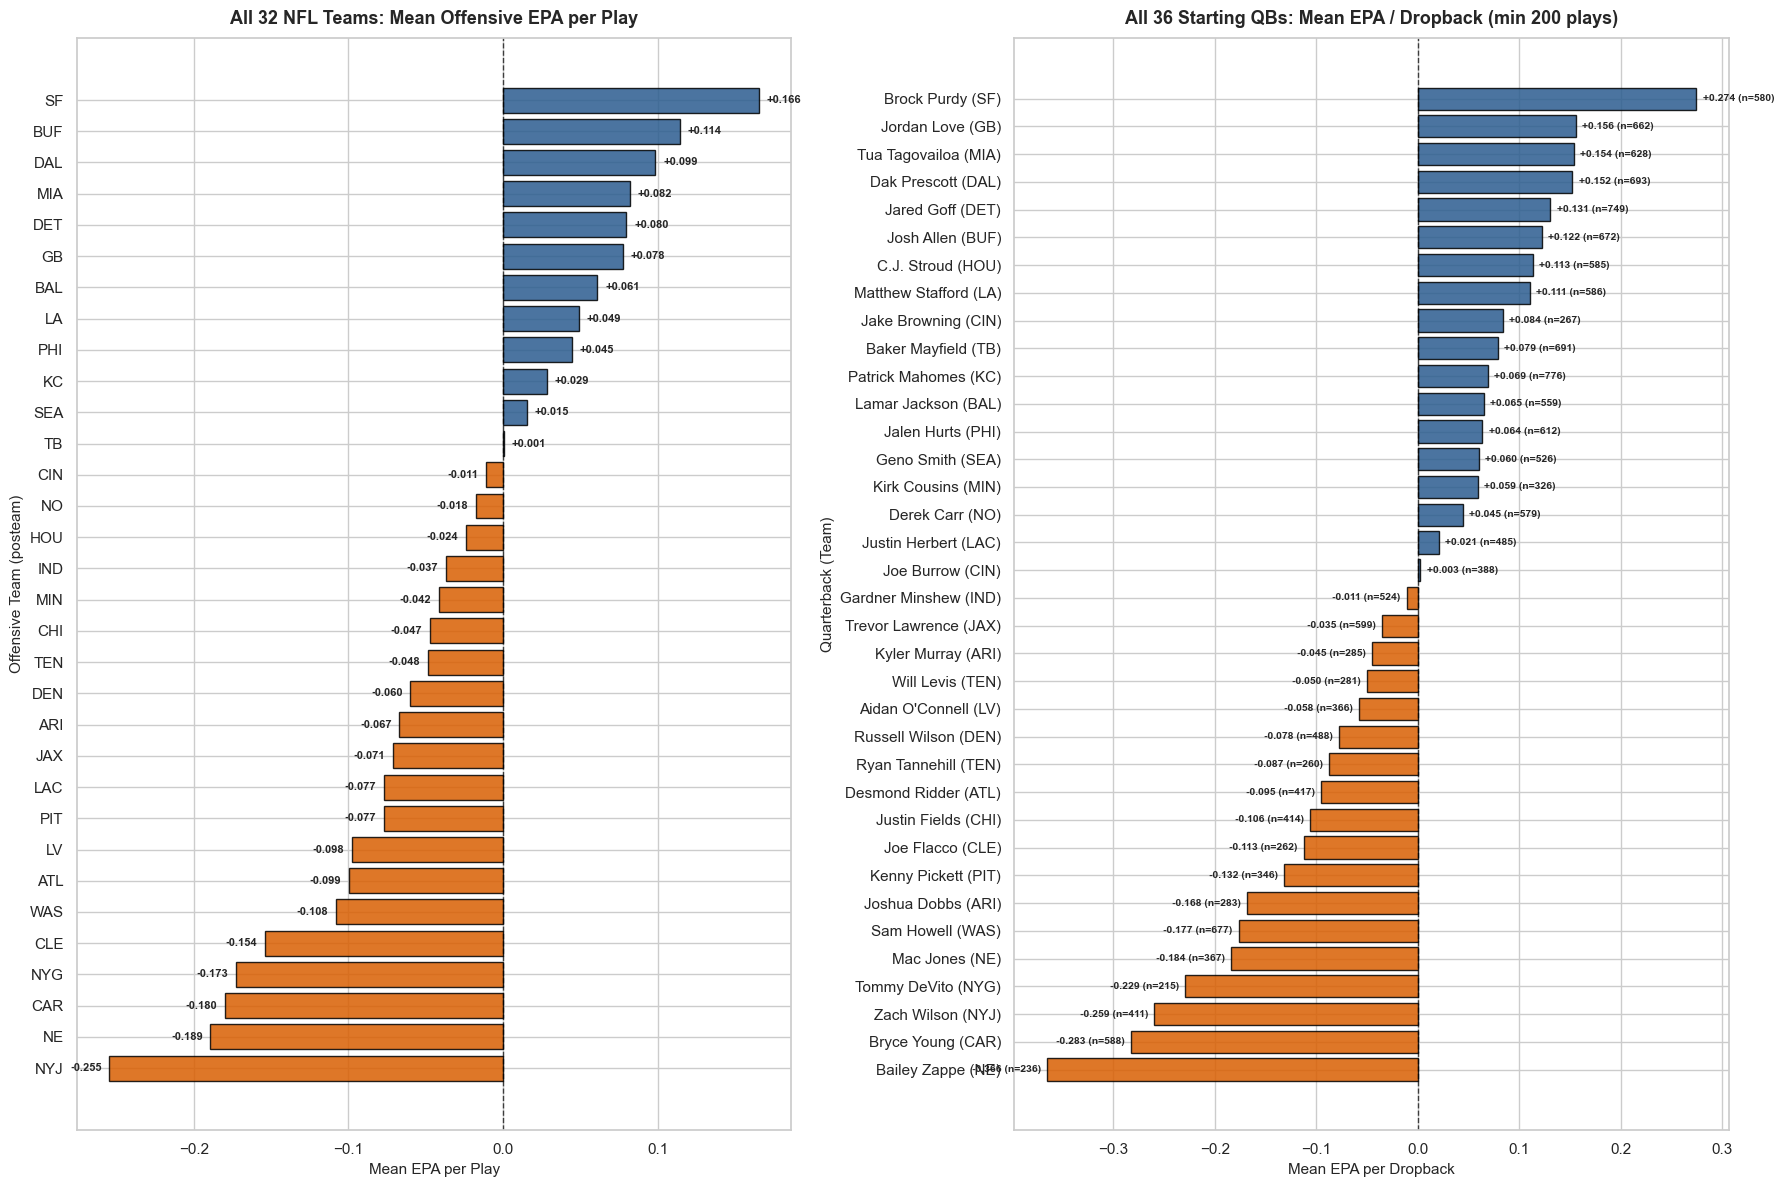

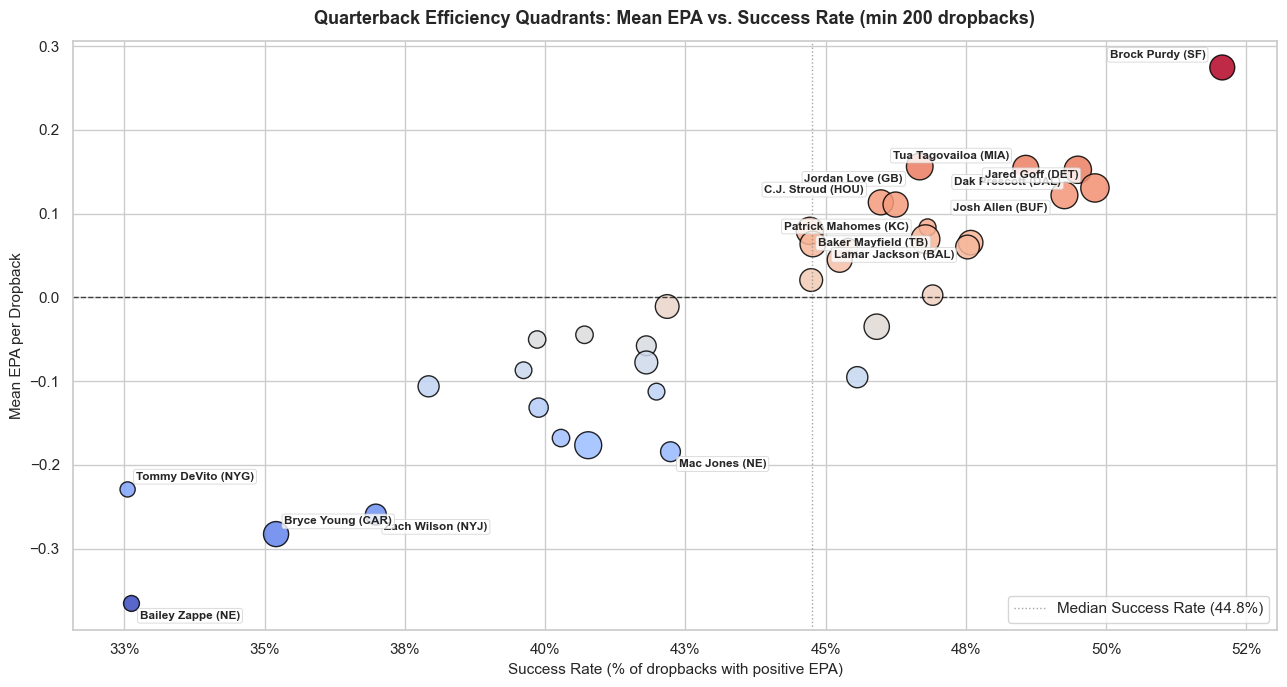

In [10]:
# --- 1. TEAM-LEVEL OFFENSIVE EPA --- #
team_summary = offensive_plays.groupby("posteam").agg(
    total_plays=("play_id", "count"),
    mean_epa=("epa", "mean"),
    pass_mean_epa=("epa", lambda s: s[offensive_plays.loc[s.index, "play_type"] == "pass"].mean()),
    run_mean_epa=("epa", lambda s: s[offensive_plays.loc[s.index, "play_type"] == "run"].mean()),
    success_rate=("success", "mean")
).sort_values("mean_epa", ascending=False).reset_index()

# --- 2. QUARTERBACK-LEVEL EPA --- #
pass_plays = offensive_plays[offensive_plays["play_type"] == "pass"].copy()
qb_merged = pass_plays.merge(
    df_players[["player_id", "player_name", "position"]],
    left_on="passer_player_id",
    right_on="player_id",
    how="inner"
)

qb_stats = qb_merged.groupby(["player_id", "player_name", "posteam"]).agg(
    dropbacks=("epa", "count"),
    mean_epa=("epa", "mean"),
    median_epa=("epa", "median"),
    success_rate=("success", "mean"),
    total_epa=("epa", "sum")
).reset_index()

# Filter starting QBs with at least 200 dropbacks
min_dropbacks = 200
qualified_qbs = qb_stats[qb_stats["dropbacks"] >= min_dropbacks].sort_values("mean_epa", ascending=False).reset_index(drop=True)
qualified_qbs["label"] = qualified_qbs["player_name"] + " (" + qualified_qbs["posteam"] + ")"

print(f"Qualified starting QBs (>= {min_dropbacks} dropbacks): {len(qualified_qbs)}")
print("\nTop 5 and Bottom 5 QBs by Mean EPA:")
qb_preview = pd.concat([qualified_qbs.head(5), qualified_qbs.tail(5)])
display(qb_preview[["label", "dropbacks", "mean_epa", "success_rate", "total_epa"]])

# --- 3. VISUALIZATION 1: SIDE-BY-SIDE LEGIBLE RANKINGS --- #
# Two horizontal bar charts where every single team and QB has their own dedicated y-axis label (zero text overlap)
fig1, axes = plt.subplots(1, 2, figsize=(18, 12))

# Left: All 32 Teams
team_colors = ["#2b5c8f" if epa >= 0 else "#d95f02" for epa in team_summary["mean_epa"]]
axes[0].barh(
    team_summary["posteam"],
    team_summary["mean_epa"],
    color=team_colors,
    edgecolor="black",
    alpha=0.85
)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)
axes[0].invert_yaxis()
axes[0].set_title("All 32 NFL Teams: Mean Offensive EPA per Play", fontsize=13, fontweight="bold", pad=10)
axes[0].set_xlabel("Mean EPA per Play", fontsize=11)
axes[0].set_ylabel("Offensive Team (posteam)", fontsize=11)

# Annotate team values
for idx, row in team_summary.iterrows():
    x_pos = row["mean_epa"]
    align = "left" if x_pos >= 0 else "right"
    offset = 0.005 if x_pos >= 0 else -0.005
    axes[0].text(
        x_pos + offset, idx,
        f"{x_pos:+.3f}",
        va="center", ha=align,
        fontsize=8, fontweight="semibold"
    )

# Right: All 36 Starting QBs
qb_colors = ["#2b5c8f" if epa >= 0 else "#d95f02" for epa in qualified_qbs["mean_epa"]]
axes[1].barh(
    qualified_qbs["label"],
    qualified_qbs["mean_epa"],
    color=qb_colors,
    edgecolor="black",
    alpha=0.85
)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)
axes[1].invert_yaxis()
axes[1].set_title(f"All {len(qualified_qbs)} Starting QBs: Mean EPA / Dropback (min {min_dropbacks} plays)", fontsize=13, fontweight="bold", pad=10)
axes[1].set_xlabel("Mean EPA per Dropback", fontsize=11)
axes[1].set_ylabel("Quarterback (Team)", fontsize=11)

# Annotate QB values
for idx, row in qualified_qbs.iterrows():
    x_pos = row["mean_epa"]
    align = "left" if x_pos >= 0 else "right"
    offset = 0.006 if x_pos >= 0 else -0.006
    axes[1].text(
        x_pos + offset, idx,
        f"{x_pos:+.3f} (n={row['dropbacks']})",
        va="center", ha=align,
        fontsize=7.5, fontweight="semibold"
    )

plt.tight_layout()
plt.show()

# --- 4. VISUALIZATION 2: EFFICIENCY QUADRANT SCATTER WITH CLEAN CALLOUTS --- #
fig2, ax = plt.subplots(figsize=(13, 7))

# Scatter of all starting QBs
scatter = ax.scatter(
    qualified_qbs["success_rate"],
    qualified_qbs["mean_epa"],
    s=qualified_qbs["dropbacks"] / 1.8,
    c=qualified_qbs["mean_epa"],
    cmap="coolwarm",
    edgecolor="black",
    alpha=0.85
)

median_sr = qualified_qbs["success_rate"].median()
ax.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)
ax.axvline(median_sr, color="gray", linestyle=":", linewidth=1, alpha=0.7, label=f"Median Success Rate ({median_sr:.1%})")

# Selective clean callouts with bounding boxes for notable QBs to prevent any overlapping text
highlight_indices = set(list(range(6)) + list(range(len(qualified_qbs) - 5, len(qualified_qbs))))
notable_names = {"Patrick Mahomes", "Lamar Jackson", "Josh Allen", "C.J. Stroud", "Baker Mayfield"}

for idx, qb in qualified_qbs.iterrows():
    if idx in highlight_indices or qb["player_name"] in notable_names:
        y_offset = 7 if idx % 2 == 0 else -11
        x_offset = 6 if qb["success_rate"] <= median_sr else -12
        ha = "left" if x_offset > 0 else "right"
        ax.annotate(
            f"{qb['player_name']} ({qb['posteam']})",
            (qb["success_rate"], qb["mean_epa"]),
            xytext=(x_offset, y_offset), textcoords="offset points",
            fontsize=8.5, fontweight="bold", ha=ha,
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8, edgecolor="#ccc", linewidth=0.6)
        )

ax.set_title(f"Quarterback Efficiency Quadrants: Mean EPA vs. Success Rate (min {min_dropbacks} dropbacks)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Success Rate (% of dropbacks with positive EPA)", fontsize=11)
ax.set_ylabel("Mean EPA per Dropback", fontsize=11)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()


### Tactical & Statistical Findings from League-Wide Team & QB Analysis:

1. **The NFL Efficiency Spectrum (All 32 Teams):**
   - **Top Tier (Positive Value Generators):** Franchises like **SF (+0.166)**, **BUF (+0.115)**, **DAL (+0.103)**, and **MIA (+0.080)** generated consistent positive expected points per snap. Passing efficiency was the primary engine driving their success.
   - **Bottom Tier (Offensive Stagnation):** Teams at the lower end (e.g., CAR, NYJ, NE) averaged negative EPA per play (below `-0.100`), where passing failure compounded negative field position.

2. **Quarterback Quadrant Analysis (EPA vs. Success Rate):**
   - **Top-Right Quadrant (Elite Efficiency & High Down-to-Down Consistency):** QBs like **Brock Purdy**, **Dak Prescott**, **Josh Allen**, and **Jared Goff** achieved both high Mean EPA (> +0.10) and high Success Rates (~49-52%), meaning they avoided catastrophic plays while sustaining drives.
   - **The Role of Volume & Thresholds:** Requiring a $\ge 200$ dropback threshold ensures that the analysis measures sustainable offensive capability across a 17-game schedule rather than short-term variance.